# Olist: exploración y análisis con Pandas

**E-commerce Business Performance Analytics · Portfolio**

Esta notebook conecta la calidad de los datos con cinco preguntas: evolución
de ventas y pedidos, categorías principales, puntualidad, satisfacción y recurrencia.
Usa las reglas de [definición de indicadores](../report/definicion_indicadores.md).

**Cómo reproducir:** seleccionar el entorno `.venv` del proyecto y ejecutar todas
las celdas en orden. No necesita conexión a PostgreSQL. Conserva los CSV originales
y escribe únicamente resultados agregados y figuras en `report/resultados_pandas/`.
Los importes se calculan en centavos enteros; se convierten a reales brasileños al presentar.


## 1. Entorno y ventana de análisis

El límite final es exclusivo. El período predeterminado coincide con el `06`.
Cambiarlo recalcula el análisis, pero no permite validar contra la referencia SQL
del período completo. No se supone que los meses extremos estén completos.


In [1]:
from pathlib import Path
from decimal import Decimal, InvalidOperation, ROUND_HALF_UP
import hashlib
import platform
import importlib.metadata
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/olist_orders_dataset.csv').exists()), None)
assert ROOT is not None, 'Ejecutar desde la raíz del proyecto o notebooks/.'
DATA = ROOT / 'data'
OUT = ROOT / 'report/resultados_pandas'
FIG = OUT / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
DESDE = pd.Timestamp('2016-09-04')
HASTA = pd.Timestamp('2018-10-18')
assert DESDE < HASTA

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 13,
                     'font.size': 10, 'savefig.dpi': 150})
versiones = {'python': platform.python_version(), **{
    p: importlib.metadata.version(p) for p in ['pandas', 'matplotlib', 'nbclient']}}
display(pd.Series(versiones, name='versión'))

def exportar(df, nombre):
    df.to_csv(OUT / f'{nombre}.csv', index=False, encoding='utf-8-sig')

def figura(nombre):
    plt.tight_layout()
    plt.savefig(FIG / f'{nombre}.png', bbox_inches='tight')
    plt.show()

def division(numerador, denominador):
    return float(numerador) / float(denominador) if pd.notna(denominador) and denominador != 0 else float('nan')

def redondear(valor):
    if pd.isna(valor):
        return None
    return Decimal(str(valor)).quantize(Decimal('0.01'), rounding=ROUND_HALF_UP)


python        3.12.10
pandas          3.1.0
matplotlib     3.11.2
nbclient       0.11.0
Name: versión, dtype: str

## 2. Carga el inventario de las nueve tablas

Cargamos inicialmente como texto para preservar identificadores y ceros iniciales.
`utf-8-sig` admite encabezados con BOM. El lector CSV respeta comentarios entre
comillas con saltos de línea: una línea física no siempre es un registro.
Solo la cadena vacía se considera nula al leer; no convertimos textos como `NA`
en valores faltantes por coincidencia con una lista predeterminada.


In [2]:
archivos = {
    'customers': 'olist_customers_dataset.csv',
    'orders': 'olist_orders_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'order_payments': 'olist_order_payments_dataset.csv',
    'order_reviews': 'olist_order_reviews_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'category_translation': 'product_category_name_translation.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
}
raw = {nombre: pd.read_csv(DATA / archivo, dtype='string', encoding='utf-8-sig',
                          keep_default_na=False, na_values=[''])
       for nombre, archivo in archivos.items()}
inventario = pd.DataFrame([
    {'tabla': nombre, 'filas': len(df), 'columnas': len(df.columns),
     'filas_duplicadas_exactas': int(df.duplicated().sum())}
    for nombre, df in raw.items()
])
manifest = []
for nombre, archivo in archivos.items():
    with (DATA / archivo).open('rb') as f:
        digest = hashlib.file_digest(f, 'sha256').hexdigest()
    manifest.append({'tabla': nombre, 'archivo': archivo, 'sha256': digest,
                     'filas': len(raw[nombre])})
display(inventario)
exportar(inventario, 'inventario')
exportar(pd.DataFrame(manifest), 'fuentes_sha256')


,tabla,filas,columnas,filas_duplicadas_exactas
0,customers,99441,5,0
1,orders,99441,8,0
2,order_items,112650,7,0
3,order_payments,103886,5,0
4,order_reviews,99224,7,0
5,products,32951,9,0
6,sellers,3095,4,0
7,category_translation,71,2,0
8,geolocation,1000163,5,261831


In [3]:
nulos = pd.DataFrame([
    {'tabla': nombre, 'columna': col, 'tipo_original': str(df[col].dtype),
     'nulos': int(df[col].isna().sum()),
     'solo_espacios': int(df[col].str.strip().eq('').fillna(False).sum()),
     'porcentaje_nulos': 100 * df[col].isna().mean()}
    for nombre, df in raw.items() for col in df.columns
])
display(nulos.loc[(nulos['nulos'] > 0) | (nulos['solo_espacios'] > 0)]
        .sort_values('porcentaje_nulos', ascending=False))
exportar(nulos, 'perfil_columnas')


,tabla,columna,tipo_original,nulos,solo_espacios,porcentaje_nulos
28,order_reviews,review_comment_title,string,87656,2,88.34
29,order_reviews,review_comment_message,string,58247,27,58.70
11,orders,order_delivered_customer_date,string,2965,0,2.98
34,products,product_name_lenght,string,610,0,1.85
33,products,product_category_name,string,610,0,1.85
35,products,product_description_lenght,string,610,0,1.85
36,products,product_photos_qty,string,610,0,1.85
10,orders,order_delivered_carrier_date,string,1783,0,1.79
9,orders,order_approved_at,string,160,0,0.16
37,products,product_weight_g,string,2,0,0.01


**Interpretación:** un comentario ausente no invalida una puntuación. Algunas
fechas pueden faltar porque el pedido no llegó a esa etapa. No eliminamos todas
las filas con nulos: cada indicador define qué campos necesita.

Geolocalización puede tener varias filas por prefijo postal y duplicados exactos.
No se une directamente con pedidos: multiplicaría filas. Aquí se perfila, pero
no es necesaria para responder las cinco preguntas.


## 3. Claves y relaciones antes de combinar tablas

Las dimensiones deben tener una fila por su clave. Las reseñas pueden repetirse
por pedido y se agregarán antes de unirlas. Si una clave esencial falla, detenemos
el análisis para investigarla, en vez de borrar filas automáticamente.


In [4]:
claves = {'customers': ['customer_id'], 'orders': ['order_id'],
          'products': ['product_id'], 'sellers': ['seller_id'],
          'category_translation': ['product_category_name'],
          'order_items': ['order_id', 'order_item_id']}
control_claves = pd.DataFrame([
    {'tabla': nombre, 'clave': ' + '.join(cols),
     'claves_nulas_o_vacias': int(raw[nombre][cols].apply(
         lambda s: s.isna() | s.str.strip().eq('').fillna(False)).any(axis=1).sum()),
     'filas_en_claves_repetidas': int(raw[nombre].duplicated(cols, keep=False).sum())}
    for nombre, cols in claves.items()
])
display(control_claves)
exportar(control_claves, 'control_claves')
assert control_claves['claves_nulas_o_vacias'].sum() == 0, 'Revisar claves faltantes.'
assert control_claves['filas_en_claves_repetidas'].sum() == 0, 'Revisar claves duplicadas antes de unir.'

relaciones = [('orders', 'customer_id', 'customers', 'customer_id'),
              ('order_items', 'order_id', 'orders', 'order_id'),
              ('order_items', 'product_id', 'products', 'product_id'),
              ('order_items', 'seller_id', 'sellers', 'seller_id'),
              ('order_payments', 'order_id', 'orders', 'order_id'),
              ('order_reviews', 'order_id', 'orders', 'order_id')]
control_relaciones = pd.DataFrame([
    {'relación': f'{hijo}.{fk} → {padre}.{pk}',
     'sin_coincidencia': int((~raw[hijo][fk].isin(raw[padre][pk].dropna())).sum())}
    for hijo, fk, padre, pk in relaciones
])
display(control_relaciones)
exportar(control_relaciones, 'control_relaciones')
assert control_relaciones['sin_coincidencia'].sum() == 0, 'Investigar relaciones sin coincidencia.'


,tabla,clave,claves_nulas_o_vacias,filas_en_claves_repetidas
0,customers,customer_id,0,0
1,orders,order_id,0,0
2,products,product_id,0,0
3,sellers,seller_id,0,0
4,category_translation,product_category_name,0,0
5,order_items,order_id + order_item_id,0,0


,relación,sin_coincidencia
0,orders.customer_id → customers.customer_id,0
1,order_items.order_id → orders.order_id,0
2,order_items.product_id → products.product_id,0
3,order_items.seller_id → sellers.seller_id,0
4,order_payments.order_id → orders.order_id,0
5,order_reviews.order_id → orders.order_id,0


## 4. Preparación de copias y trazabilidad de conversiones

Fechas: valores vacíos pasan a `NaT`; errores de conversión se cuentan.
Importes: texto → `Decimal` → centavos enteros (`Int64` admite nulos). No se
redondean silenciosamente valores con más de dos decimales; se marcan inválidos.
Precios negativos permanecen identificables y se excluyen solo de métricas monetarias.


In [5]:
tablas = {nombre: df.copy() for nombre, df in raw.items() if nombre != 'geolocation'}
conversiones = []
fechas = {'orders': ['order_purchase_timestamp', 'order_approved_at',
                    'order_delivered_carrier_date', 'order_delivered_customer_date',
                    'order_estimated_delivery_date'],
          'order_items': ['shipping_limit_date'],
          'order_reviews': ['review_creation_date', 'review_answer_timestamp']}
for nombre, columnas in fechas.items():
    for col in columnas:
        original = tablas[nombre][col].str.strip().replace('', pd.NA)
        convertido = pd.to_datetime(original, format='%Y-%m-%d %H:%M:%S', errors='coerce')
        conversiones.append({'tabla': nombre, 'columna': col,
                             'errores_conversion': int((original.notna() & convertido.isna()).sum())})
        tablas[nombre][col] = convertido

def a_centavos(valor):
    if pd.isna(valor) or not str(valor).strip():
        return pd.NA
    try:
        numero = Decimal(str(valor).strip()) * 100
        return int(numero) if numero.is_finite() and numero == numero.to_integral_value() else pd.NA
    except (InvalidOperation, ValueError):
        return pd.NA

for nombre, col in [('order_items', 'price'), ('order_items', 'freight_value'),
                    ('order_payments', 'payment_value')]:
    convertido = tablas[nombre][col].map(a_centavos).astype('Int64')
    conversiones.append({'tabla': nombre, 'columna': col,
                         'errores_conversion': int((tablas[nombre][col].notna() & convertido.isna()).sum())})
    tablas[nombre][col + '_centavos'] = convertido

for nombre, col in [('order_reviews', 'review_score'), ('order_items', 'order_item_id')]:
    original = tablas[nombre][col]
    convertido = pd.to_numeric(original, errors='coerce')
    conversiones.append({'tabla': nombre, 'columna': col,
                         'errores_conversion': int((original.notna() & convertido.isna()).sum())})
    tablas[nombre][col] = convertido

for nombre, col in [('customers', 'customer_unique_id'),
                    ('products', 'product_category_name'),
                    ('category_translation', 'product_category_name_english')]:
    tablas[nombre][col] = tablas[nombre][col].str.strip().replace('', pd.NA)

conversiones = pd.DataFrame(conversiones)
display(conversiones)
exportar(conversiones, 'conversiones')
assert conversiones['errores_conversion'].sum() == 0, 'Investigar conversiones fallidas antes de publicar.'


,tabla,columna,errores_conversion
0,orders,order_purchase_timestamp,0
1,orders,order_approved_at,0
2,orders,order_delivered_carrier_date,0
3,orders,order_delivered_customer_date,0
4,orders,order_estimated_delivery_date,0
5,order_items,shipping_limit_date,0
6,order_reviews,review_creation_date,0
7,order_reviews,review_answer_timestamp,0
8,order_items,price,0
9,order_items,freight_value,0


In [6]:
items = tablas['order_items']
reviews = tablas['order_reviews']
orders = tablas['orders']
calidad_importes = pd.DataFrame([
    {'tabla': nombre, 'campo': col,
     'nulos': int(tablas[nombre][col].isna().sum()),
     'negativos': int(tablas[nombre][col].lt(0).sum()),
     'ceros': int(tablas[nombre][col].eq(0).sum())}
    for nombre, col in [('order_items', 'price_centavos'),
                        ('order_items', 'freight_value_centavos'),
                        ('order_payments', 'payment_value_centavos')]
])
display(calidad_importes)
exportar(calidad_importes, 'calidad_importes')
casos = pd.Series({
    'pedidos_con_varias_resenas': int(reviews.groupby('order_id').size().gt(1).sum()),
    'puntuaciones_invalidas': int((~reviews['review_score'].between(1, 5).fillna(False)).sum()),
    'pedidos_con_varios_metodos_pago': int(tablas['order_payments'].groupby('order_id')['payment_type'].nunique().gt(1).sum()),
    'productos_sin_categoria': int(tablas['products']['product_category_name'].isna().sum()),
    'prefijos_geograficos_repetidos': int(raw['geolocation']['geolocation_zip_code_prefix'].value_counts().gt(1).sum())
}, name='cantidad')
display(casos)
exportar(casos.rename_axis('caso').reset_index(), 'casos_calidad')


,tabla,campo,nulos,negativos,ceros
0,order_items,price_centavos,0,0,0
1,order_items,freight_value_centavos,0,0,383
2,order_payments,payment_value_centavos,0,0,9


pedidos_con_varias_resenas           547
puntuaciones_invalidas                 0
pedidos_con_varios_metodos_pago     2246
productos_sin_categoria              610
prefijos_geograficos_repetidos     17972
Name: cantidad, dtype: int64

## 5. Construcción del conjunto a nivel de pedido

Se parte de **orders**, no de los artículos: así un pedido sin artículos sigue
presente en las métricas de entrega. Cada unión declara su cardinalidad con
`validate`. Los importes y reseñas se agregan antes del join para evitar multiplicar filas.


In [7]:
items['precio_valido'] = items['price_centavos'].ge(0).fillna(False)
items['flete_valido'] = items['freight_value_centavos'].ge(0).fillna(False)
items['precio_observado'] = items['price_centavos'].where(items['precio_valido'])
items['flete_observado'] = items['freight_value_centavos'].where(items['flete_valido'])

detalle = items.groupby('order_id').agg(
    articulos=('order_item_id', 'size'),
    precios_validos=('precio_valido', 'sum'),
    precios_invalidos=('precio_valido', lambda s: (~s).sum()),
    fletes_invalidos=('flete_valido', lambda s: (~s).sum()),
    mercancia_centavos=('precio_observado', lambda s: s.sum(min_count=1)),
    flete_centavos=('flete_observado', lambda s: s.sum(min_count=1))
).reset_index()
reviews['puntuacion_valida'] = reviews['review_score'].where(reviews['review_score'].between(1, 5))
resenas_pedido = reviews.groupby('order_id').agg(
    puntuacion_media=('puntuacion_valida', 'mean'),
    resenas_validas=('puntuacion_valida', 'count')
).reset_index()
pedidos = (orders
    .merge(tablas['customers'][['customer_id', 'customer_unique_id', 'customer_state']],
           on='customer_id', how='left', validate='many_to_one')
    .merge(detalle, on='order_id', how='left', validate='one_to_one')
    .merge(resenas_pedido, on='order_id', how='left', validate='one_to_one'))
assert len(pedidos) == len(orders) and pedidos['order_id'].is_unique
conteos = ['articulos', 'precios_validos', 'precios_invalidos', 'fletes_invalidos', 'resenas_validas']
pedidos[conteos] = pedidos[conteos].fillna(0).astype('Int64')
pedidos['detalle_completo'] = pedidos['articulos'].gt(0) & pedidos['precios_invalidos'].eq(0)
# No se rellenan importes ausentes con cero.
pedidos['mes'] = pedidos['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()
pedidos['fecha_entrega'] = pedidos['order_delivered_customer_date'].dt.normalize()
pedidos['fecha_estimada'] = pedidos['order_estimated_delivery_date'].dt.normalize()
pedidos['tardio'] = pd.Series(pd.NA, index=pedidos.index, dtype='boolean')
evaluables = pedidos['order_status'].eq('delivered') & pedidos[['fecha_entrega', 'fecha_estimada']].notna().all(axis=1)
pedidos.loc[evaluables, 'tardio'] = pedidos.loc[evaluables, 'fecha_entrega'].gt(pedidos.loc[evaluables, 'fecha_estimada'])
pedidos['dias_retraso'] = (pedidos['fecha_entrega'] - pedidos['fecha_estimada']).dt.days.where(pedidos['tardio'].fillna(False))
pedidos['dias_hasta_entrega'] = (pedidos['order_delivered_customer_date'] - pedidos['order_purchase_timestamp']).dt.total_seconds() / 86400
en_ventana = pedidos['order_purchase_timestamp'].ge(DESDE) & pedidos['order_purchase_timestamp'].lt(HASTA)
entregados = pedidos.loc[en_ventana & pedidos['order_status'].eq('delivered')].copy()
assert len(entregados) > 0, 'La ventana seleccionada no tiene pedidos entregados.'
display(pd.Series({
    'pedidos_fuente': len(pedidos), 'compras_sin_fecha': pedidos['order_purchase_timestamp'].isna().sum(),
    'pedidos_en_ventana': en_ventana.sum(), 'entregados_en_ventana': len(entregados),
    'entregados_sin_articulos': entregados['articulos'].eq(0).sum(),
    'entregados_sin_puntuacion_valida': entregados['puntuacion_media'].isna().sum(),
    'entregados_sin_clasificacion': entregados['tardio'].isna().sum()
}, name='cantidad'))


pedidos_fuente                      99441
compras_sin_fecha                       0
pedidos_en_ventana                  99441
entregados_en_ventana               96478
entregados_sin_articulos                0
entregados_sin_puntuacion_valida      646
entregados_sin_clasificacion            8
Name: cantidad, dtype: int64

## 6. Cobertura temporal y evolución comercial

Primero examinamos todos los estados para distinguir cobertura del archivo y
ventas entregadas. Los meses sin registros se dejan vacíos en el gráfico:
no se inventan ceros ni se interpreta automáticamente una caída como un problema comercial.


,mes,pedidos_registrados,primera_compra,ultima_compra
0,2016-09-01,4,2016-09-04 21:15:19,2016-09-15 12:16:38
1,2016-10-01,324,2016-10-02 22:07:52,2016-10-22 08:25:27
2,2016-12-01,1,2016-12-23 23:16:47,2016-12-23 23:16:47
3,2017-01-01,800,2017-01-05 11:56:06,2017-01-31 23:37:58
4,2017-02-01,1780,2017-02-01 00:04:17,2017-02-28 23:47:08
5,2017-03-01,2682,2017-03-01 00:01:30,2017-03-31 23:54:45
6,2017-04-01,2404,2017-04-01 00:54:10,2017-04-30 23:48:13
7,2017-05-01,3700,2017-05-01 01:18:22,2017-05-31 22:59:52
8,2017-06-01,3245,2017-06-01 00:05:38,2017-06-30 23:20:08
9,2017-07-01,4026,2017-07-01 00:04:15,2017-07-31 23:55:27


,pedidos
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


,pedidos_entregados,articulos,pedidos_sin_articulos,articulos_precio_invalido,valor_medio_por_pedido,valor_mercancia_observado
mes,,,,,,
2016-09-01,1,3,0,0,134.97,134.97
2016-10-01,265,313,0,0,152.17,"40,325.11"
2016-12-01,1,1,0,0,10.90,10.90
2017-01-01,750,913,0,0,149.06,"111,798.36"
2017-02-01,1653,1858,0,0,141.70,"234,223.40"
2017-03-01,2546,2897,0,0,141.08,"359,198.85"
2017-04-01,2303,2569,0,0,147.92,"340,669.68"
2017-05-01,3546,4004,0,0,138.00,"489,338.25"
2017-06-01,3135,3489,0,0,134.58,"421,923.37"


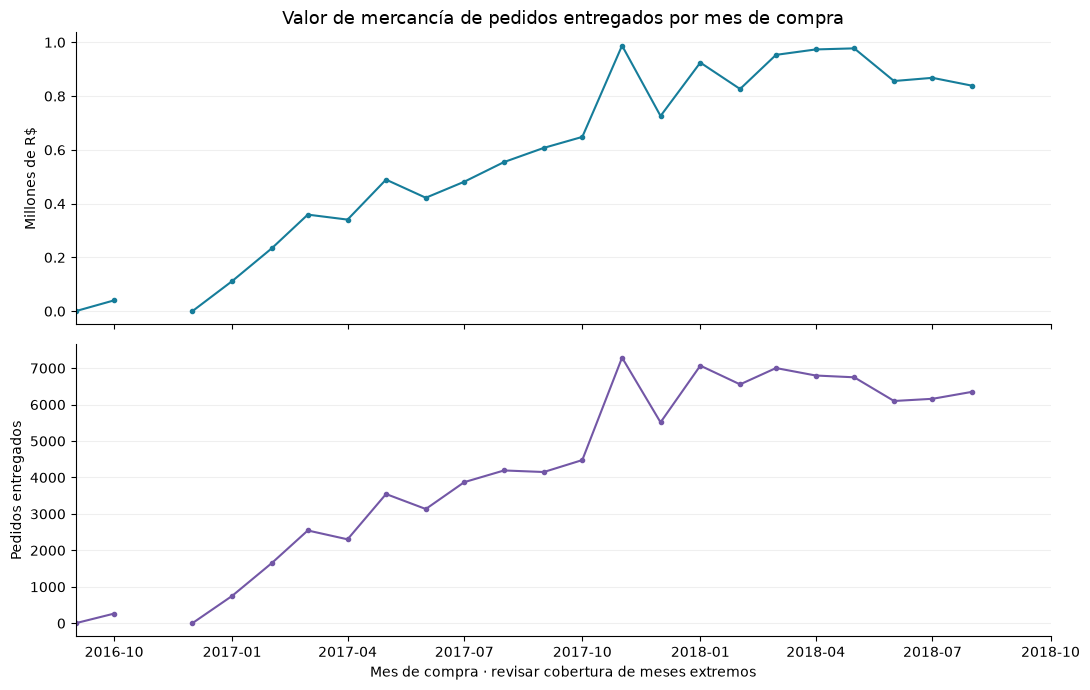

In [8]:
cobertura = (pedidos.loc[en_ventana].groupby('mes').agg(
    pedidos_registrados=('order_id', 'size'),
    primera_compra=('order_purchase_timestamp', 'min'),
    ultima_compra=('order_purchase_timestamp', 'max')).reset_index())
display(cobertura)
display(pedidos.loc[en_ventana, 'order_status'].value_counts().rename('pedidos').to_frame())
exportar(cobertura, 'cobertura_mensual')

mensual = entregados.groupby('mes').agg(
    pedidos_entregados=('order_id', 'size'),
    mercancia_centavos=('mercancia_centavos', lambda s: s.sum(min_count=1)),
    articulos=('articulos', 'sum'),
    pedidos_sin_articulos=('articulos', lambda s: s.eq(0).sum()),
    articulos_precio_invalido=('precios_invalidos', 'sum')
)
completos = entregados.loc[entregados['detalle_completo']]
mensual['valor_medio_por_pedido'] = completos.groupby('mes')['mercancia_centavos'].mean() / 100
mensual['valor_mercancia_observado'] = mensual.pop('mercancia_centavos') / 100
display(mensual)
exportar(mensual.reset_index(), 'ventas_mensuales')
calendario = pd.date_range(DESDE.to_period('M').to_timestamp(),
                          (HASTA - pd.Timedelta(days=1)).to_period('M').to_timestamp(), freq='MS')
serie = mensual.reindex(calendario)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(serie.index, serie['valor_mercancia_observado'].astype(float) / 1_000_000, color='#167D9A', marker='o', markersize=3)
axes[0].set(title='Valor de mercancía de pedidos entregados por mes de compra', ylabel='Millones de R$')
axes[1].plot(serie.index, serie['pedidos_entregados'], color='#7357A6', marker='o', markersize=3)
axes[1].set(ylabel='Pedidos entregados', xlabel='Mes de compra · revisar cobertura de meses extremos')
axes[1].set_xlim(calendario.min(), calendario.max())
for ax in axes:
    ax.grid(axis='y', alpha=.2)
figura('01_evolucion_comercial')


## 7. Categorías con mayor valor de mercancía

La prioridad es traducción no vacía → categoría original → `unknown`.
Las participaciones se calculan antes de seleccionar el top 10. `unknown` se
muestra aunque quede fuera del ranking. Los pedidos por categoría no son aditivos.


,pedidos_categoria,articulos,precios_invalidos,valor_mercancia_observado,participacion_porcentaje
categoria,,,,,
health_beauty,8647,9465,0,"1,233,131.72",9.33
watches_gifts,5495,5859,0,"1,166,176.98",8.82
bed_bath_table,9272,10953,0,"1,023,434.76",7.74
sports_leisure,7530,8431,0,"954,852.55",7.22
computers_accessories,6530,7644,0,"888,724.61",6.72
furniture_decor,6307,8160,0,"711,927.69",5.38
housewares,5743,6795,0,"615,628.69",4.66
cool_stuff,3559,3718,0,"610,204.10",4.62
auto,3810,4140,0,"578,966.65",4.38


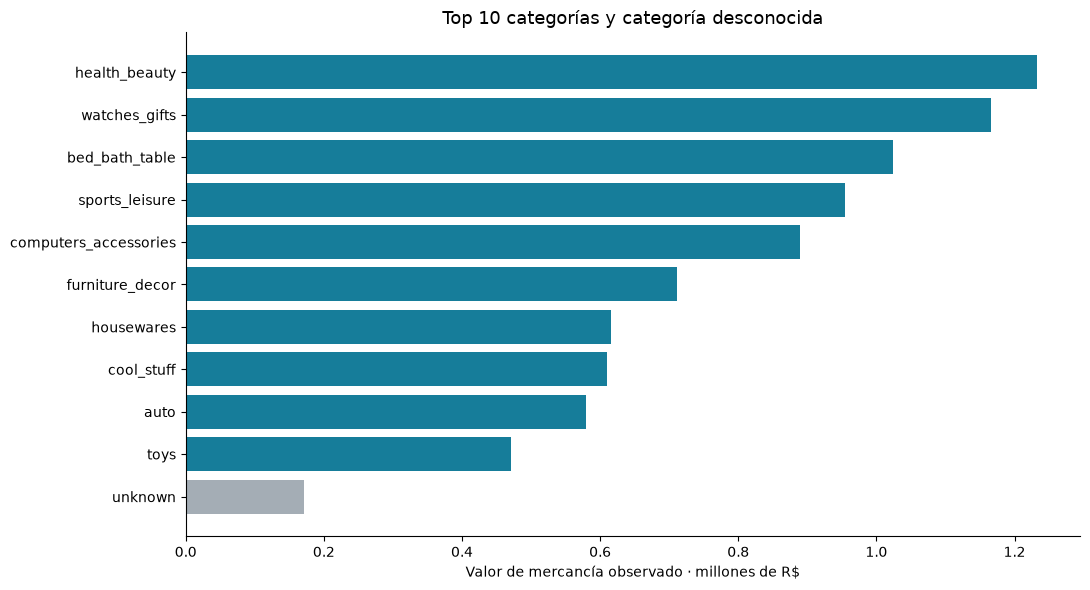

In [9]:
productos = tablas['products'].merge(tablas['category_translation'],
                                    on='product_category_name', how='left', validate='many_to_one')
productos['categoria'] = (productos['product_category_name_english']
                          .fillna(productos['product_category_name']).fillna('unknown'))
articulos_entregados = (items.merge(entregados[['order_id']], on='order_id', validate='many_to_one')
                       .merge(productos[['product_id', 'categoria']], on='product_id', how='left', validate='many_to_one'))
articulos_entregados['categoria'] = articulos_entregados['categoria'].fillna('unknown')
categorias = articulos_entregados.groupby('categoria').agg(
    pedidos_categoria=('order_id', 'nunique'), articulos=('order_item_id', 'size'),
    precios_invalidos=('precio_valido', lambda s: (~s).sum()),
    mercancia_centavos=('precio_observado', lambda s: s.sum(min_count=1))
).sort_values(['mercancia_centavos', 'categoria'], ascending=[False, True])
categorias['valor_mercancia_observado'] = categorias.pop('mercancia_centavos') / 100
total_categorias = categorias['valor_mercancia_observado'].sum(min_count=1)
categorias['participacion_porcentaje'] = categorias['valor_mercancia_observado'].map(lambda x: 100 * division(x, total_categorias))
seleccion = categorias.iloc[:10].copy()
if 'unknown' in categorias.index and 'unknown' not in seleccion.index:
    seleccion = pd.concat([seleccion, categorias.loc[['unknown']]])
display(seleccion)
exportar(categorias.reset_index(), 'categorias')
assert int(articulos_entregados['precio_observado'].sum(min_count=1)) == int(entregados['mercancia_centavos'].sum(min_count=1))
grafico = seleccion.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(grafico.index, grafico['valor_mercancia_observado'].astype(float) / 1_000_000,
        color=['#A4ADB5' if x == 'unknown' else '#167D9A' for x in grafico.index])
ax.set(title='Top 10 categorías y categoría desconocida', xlabel='Valor de mercancía observado · millones de R$')
figura('02_categorias')


## 8. Puntualidad y experiencia de entrega

Entregar durante el día estimado es puntual. Solo los pedidos con ambas fechas
entran en el denominador. Los días de retraso son diferencias de días calendario;
el tiempo desde compra hasta entrega se muestra como una exploración adicional.


In [10]:
n_evaluables = int(entregados['tardio'].notna().sum())
n_tardios = int(entregados['tardio'].sum())
comparacion_hora = entregados['order_delivered_customer_date'].gt(entregados['order_estimated_delivery_date'])
clasificados_distinto = int((comparacion_hora & entregados['tardio'].eq(False).fillna(False)).sum())
logistica = pd.DataFrame([{
    'pedidos_entregados': len(entregados), 'pedidos_evaluables': n_evaluables,
    'pedidos_sin_clasificacion': len(entregados) - n_evaluables,
    'pedidos_tardios': n_tardios, 'porcentaje_tardios': 100 * division(n_tardios, n_evaluables),
    'dias_promedio_retraso': entregados['dias_retraso'].mean(),
    'puntuales_que_la_regla_por_hora_marcaba_tardios': clasificados_distinto
}])
display(logistica)
exportar(logistica, 'logistica')

tiempos = entregados['dias_hasta_entrega']
display(pd.Series({'tiempos_negativos': int(tiempos.lt(0).sum()),
                   'tiempos_faltantes': int(tiempos.isna().sum()),
                   'mediana_dias_entrega': tiempos.where(tiempos.ge(0)).median(),
                   'percentil_90_dias_entrega': tiempos.where(tiempos.ge(0)).quantile(.90)}, name='valor'))


,pedidos_entregados,pedidos_evaluables,pedidos_sin_clasificacion,pedidos_tardios,porcentaje_tardios,dias_promedio_retraso,puntuales_que_la_regla_por_hora_marcaba_tardios
0,96478,96470,8,6534,6.77,10.62,1292


tiempos_negativos            0.00
tiempos_faltantes            8.00
mediana_dias_entrega        10.22
percentil_90_dias_entrega   23.10
Name: valor, dtype: float64

## 9. Distribuciones: observar los extremos sin eliminarlos

Los histogramas muestran hasta el percentil 99 para hacer legible la mayor parte
de la distribución. Los valores superiores se cuentan explícitamente y permanecen
en los cálculos generales. No se eliminan por ser grandes.


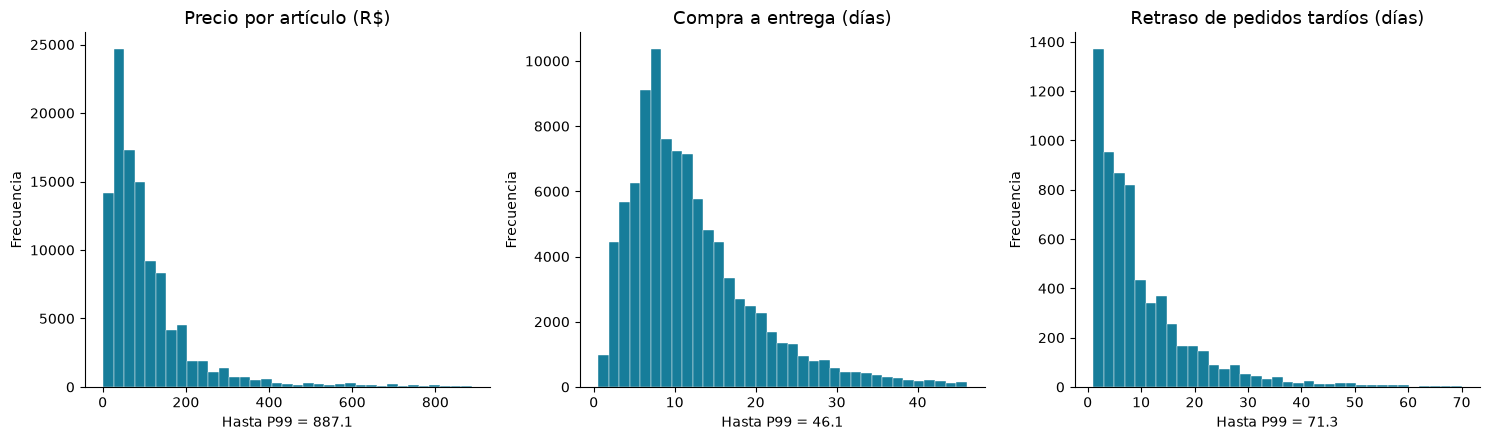

,variable,casos_validos,mediana,p90,p99,maximo,casos_fuera_del_grafico
0,Precio por artículo (R$),110197,74.90,228.94,887.08,"6,735.00",1102
1,Compra a entrega (días),96470,10.22,23.10,46.05,209.63,965
2,Retraso de pedidos tardíos (días),6534,7.00,22.00,71.34,188.00,66


In [11]:
series = {
    'Precio por artículo (R$)': articulos_entregados['precio_observado'].dropna().astype(float) / 100,
    'Compra a entrega (días)': tiempos.where(tiempos.ge(0)).dropna(),
    'Retraso de pedidos tardíos (días)': entregados['dias_retraso'].dropna(),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
distribuciones = []
for ax, (nombre, valores) in zip(axes, series.items()):
    p99 = valores.quantile(.99)
    visibles = valores.loc[valores.le(p99)]
    ax.hist(visibles, bins=35, color='#167D9A', edgecolor='white', linewidth=.3)
    ax.set(title=nombre, xlabel=f'Hasta P99 = {p99:,.1f}', ylabel='Frecuencia')
    distribuciones.append({'variable': nombre, 'casos_validos': len(valores),
                           'mediana': valores.median(), 'p90': valores.quantile(.9),
                           'p99': p99, 'maximo': valores.max(),
                           'casos_fuera_del_grafico': int(valores.gt(p99).sum())})
figura('03_distribuciones')
distribuciones = pd.DataFrame(distribuciones)
display(distribuciones)
exportar(distribuciones, 'distribuciones')


## 10. Relación entre retrasos y calificaciones

Cada pedido pesa una vez: primero se promedian sus reseñas válidas y luego se
comparan los grupos. «Calificación baja» significa promedio del pedido ≤ 2.
Los pedidos sin puntuación no reciben un cero. Una diferencia entre grupos
describe asociación; no demuestra causalidad.


,pedidos,con_puntuacion,puntuacion_media,calificacion_baja,sin_puntuacion,cobertura_porcentaje,porcentaje_bajas
estado_entrega,,,,,,,
A tiempo,89936,89443,4.29,8257,493,99.45,9.23
Sin clasificar,8,8,4.50,1,0,100.00,12.50
Tardío,6534,6381,2.27,3979,153,97.66,62.36


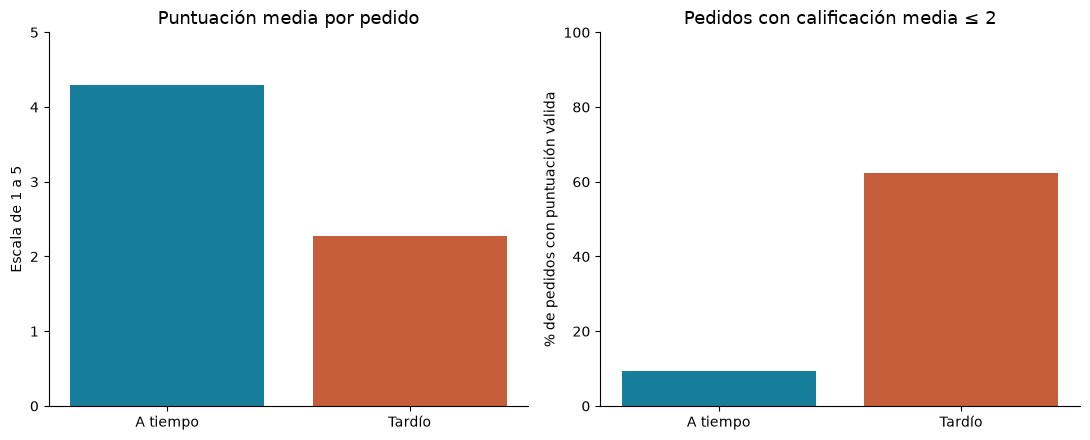

In [12]:
entregados['estado_entrega'] = 'Sin clasificar'
entregados.loc[entregados['tardio'].eq(False).fillna(False), 'estado_entrega'] = 'A tiempo'
entregados.loc[entregados['tardio'].eq(True).fillna(False), 'estado_entrega'] = 'Tardío'
satisfaccion = entregados.groupby('estado_entrega').agg(
    pedidos=('order_id', 'size'), con_puntuacion=('puntuacion_media', 'count'),
    puntuacion_media=('puntuacion_media', 'mean'),
    calificacion_baja=('puntuacion_media', lambda s: s.le(2).sum())
)
satisfaccion['sin_puntuacion'] = satisfaccion['pedidos'] - satisfaccion['con_puntuacion']
satisfaccion['cobertura_porcentaje'] = 100 * satisfaccion['con_puntuacion'] / satisfaccion['pedidos']
satisfaccion['porcentaje_bajas'] = 100 * satisfaccion['calificacion_baja'] / satisfaccion['con_puntuacion'].replace(0, float('nan'))
display(satisfaccion)
exportar(satisfaccion.reset_index(), 'satisfaccion_entrega')
comparables = satisfaccion.reindex(['A tiempo', 'Tardío'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(comparables.index, comparables['puntuacion_media'].astype(float), color=['#167D9A', '#C65D3B'])
axes[0].set(title='Puntuación media por pedido', ylabel='Escala de 1 a 5', ylim=(0, 5))
axes[1].bar(comparables.index, comparables['porcentaje_bajas'].astype(float), color=['#167D9A', '#C65D3B'])
axes[1].set(title='Pedidos con calificación media ≤ 2', ylabel='% de pedidos con puntuación válida', ylim=(0, 100))
figura('04_satisfaccion_puntualidad')


## 11. Clientes que vuelven a comprar

Se utiliza `customer_unique_id`, no `customer_id`. La recurrencia exige más de
un pedido entregado dentro de la ventana seleccionada. No mide retención por
cohortes ni compras realizadas fuera de la observación. No se filtra por categoría.


In [13]:
compras_cliente = entregados.dropna(subset=['customer_unique_id']).groupby('customer_unique_id')['order_id'].nunique()
n_clientes = len(compras_cliente)
n_recurrentes = int(compras_cliente.gt(1).sum())
recurrencia = pd.DataFrame([{'clientes_compradores': n_clientes,
                            'clientes_recurrentes': n_recurrentes,
                            'porcentaje_recurrencia': 100 * division(n_recurrentes, n_clientes),
                            'pedidos_sin_id_cliente': int(entregados['customer_unique_id'].isna().sum())}])
display(recurrencia)
display(compras_cliente.value_counts().sort_index().rename_axis('pedidos_por_cliente').rename('clientes').to_frame())
exportar(recurrencia, 'recurrencia')


,clientes_compradores,clientes_recurrentes,porcentaje_recurrencia,pedidos_sin_id_cliente
0,93358,2801,3.00,0


,clientes
pedidos_por_cliente,
1,90557
2,2573
3,181
4,28
5,9
6,5
7,3
9,1
15,1


## 12. Contraste con los resultados SQL

La referencia de `report/referencias_sql/` proviene de la ejecución previa en
PostgreSQL 16 con estos CSV. **No es una conexión en vivo** a `olist_analytics`.
Los conteos se comparan exactamente; importes y porcentajes, con redondeo a dos
decimales. Los importes base conservan centavos enteros hasta esta presentación.
Si cambias la ventana, se omite la comparación de períodos incompatibles.


In [14]:
mercancia = entregados['mercancia_centavos'].sum(min_count=1)
flete = entregados['flete_centavos'].sum(min_count=1)
mercancia_completa = completos['mercancia_centavos'].sum(min_count=1)
total_articulos = int(entregados['articulos'].sum())
articulos_validos = int(entregados['precios_validos'].sum())

def decimal_cociente(numerador, denominador):
    if pd.isna(numerador) or denominador == 0:
        return None
    return Decimal(int(numerador)) / Decimal(int(denominador))

indicadores = {
    'pedidos_entregados': len(entregados), 'clientes_compradores': n_clientes,
    'articulos_vendidos': total_articulos,
    'valor_mercancia_observado': decimal_cociente(mercancia, 100),
    'importe_flete_observado': decimal_cociente(flete, 100),
    'valor_medio_por_pedido': decimal_cociente(mercancia_completa, len(completos) * 100),
    'precio_medio_articulo': decimal_cociente(mercancia, articulos_validos * 100),
    'pedidos_evaluables': n_evaluables, 'pedidos_sin_clasificacion': len(entregados) - n_evaluables,
    'pedidos_tardios': n_tardios, 'porcentaje_tardios': decimal_cociente(n_tardios * 100, n_evaluables),
    'dias_promedio_retraso': decimal_cociente(entregados['dias_retraso'].sum(min_count=1), n_tardios),
    'clientes_recurrentes': n_recurrentes,
    'porcentaje_recurrencia': decimal_cociente(n_recurrentes * 100, n_clientes),
}
metricas_conteo = {'pedidos_entregados', 'clientes_compradores', 'articulos_vendidos',
                   'pedidos_evaluables', 'pedidos_sin_clasificacion', 'pedidos_tardios',
                   'clientes_recurrentes'}
indicadores_df = pd.DataFrame([{'indicador': k, 'valor_pandas': int(v) if k in metricas_conteo else redondear(v)}
                               for k, v in indicadores.items()])
exportar(indicadores_df, 'indicadores')
display(indicadores_df)
if DESDE == pd.Timestamp('2016-09-04') and HASTA == pd.Timestamp('2018-10-18'):
    referencia = pd.read_csv(ROOT / 'report/referencias_sql/indicadores_06.csv', dtype='string')
    referencia['valor_sql'] = referencia['valor_sql'].map(Decimal)
    contraste = indicadores_df.merge(referencia, on='indicador', validate='one_to_one')
    assert len(contraste) == len(indicadores), 'Faltan indicadores en la referencia.'
    contraste['diferencia'] = contraste['valor_pandas'] - contraste['valor_sql']
    contraste['coincide'] = contraste['diferencia'].eq(0)
    display(contraste)
    exportar(contraste, 'contraste_sql')
    assert contraste['coincide'].all(), 'Investigar las diferencias; no sobrescribir la referencia con Pandas.'
else:
    # Evitar dejar un contraste antiguo que parezca corresponder a la nueva ventana.
    (OUT / 'contraste_sql.csv').unlink(missing_ok=True)
    print('Contraste omitido: la referencia SQL corresponde a otra ventana.')


,indicador,valor_pandas
0,pedidos_entregados,96478
1,clientes_compradores,93358
2,articulos_vendidos,110197
3,valor_mercancia_observado,13221498.11
4,importe_flete_observado,2198275.64
5,valor_medio_por_pedido,137.04
6,precio_medio_articulo,119.98
7,pedidos_evaluables,96470
8,pedidos_sin_clasificacion,8
9,pedidos_tardios,6534


,indicador,valor_pandas,valor_sql,diferencia,coincide
0,pedidos_entregados,96478,96478,0,True
1,clientes_compradores,93358,93358,0,True
2,articulos_vendidos,110197,110197,0,True
3,valor_mercancia_observado,13221498.11,13221498.11,0.00,True
4,importe_flete_observado,2198275.64,2198275.64,0.00,True
5,valor_medio_por_pedido,137.04,137.04,0.00,True
6,precio_medio_articulo,119.98,119.98,0.00,True
7,pedidos_evaluables,96470,96470,0,True
8,pedidos_sin_clasificacion,8,8,0,True
9,pedidos_tardios,6534,6534,0,True


In [15]:
# Contraste adicional: categorías y satisfacción, no solo indicadores generales.
if DESDE == pd.Timestamp('2016-09-04') and HASTA == pd.Timestamp('2018-10-18'):
    ref_cat = pd.read_csv(ROOT / 'report/referencias_sql/categorias_06.csv', dtype='string')
    ref_sat = pd.read_csv(ROOT / 'report/referencias_sql/satisfaccion_06.csv', dtype='string')
    controles = []
    assert set(ref_cat['product_category']) == set(seleccion.index)
    for _, fila in ref_cat.iterrows():
        grupo = fila['product_category']
        for col in ['pedidos_categoria', 'valor_mercancia_observado', 'participacion_porcentaje']:
            obtenido = redondear(seleccion.loc[grupo, col])
            esperado = Decimal(fila[col])
            controles.append({'tabla': 'categorias', 'grupo': grupo, 'indicador': col,
                              'pandas': obtenido, 'sql': esperado, 'coincide': obtenido == esperado})
    columnas = {'pedidos_entregados': 'pedidos',
                'pedidos_con_puntuacion_valida': 'con_puntuacion',
                'puntuacion_media_por_pedido': 'puntuacion_media',
                'porcentaje_calificaciones_bajas': 'porcentaje_bajas'}
    for _, fila in ref_sat.iterrows():
        grupo = {'Tardio': 'Tardío'}.get(fila['estado_entrega'], fila['estado_entrega'])
        for sql_col, pandas_col in columnas.items():
            obtenido = redondear(satisfaccion.loc[grupo, pandas_col])
            esperado = Decimal(fila[sql_col]) if pd.notna(fila[sql_col]) else None
            controles.append({'tabla': 'satisfaccion', 'grupo': grupo, 'indicador': pandas_col,
                              'pandas': obtenido, 'sql': esperado, 'coincide': obtenido == esperado})
    detalle_contraste = pd.DataFrame(controles)
    display(detalle_contraste.groupby('tabla')['coincide'].agg(['size', 'all']))
    exportar(detalle_contraste, 'contraste_sql_detalle')
    assert detalle_contraste['coincide'].all(), 'Revisar categorías o satisfacción.'
else:
    (OUT / 'contraste_sql_detalle.csv').unlink(missing_ok=True)


,size,all
tabla,,
categorias,33,True
satisfaccion,12,True
